In [2]:
import os
import pandas as pd
from tqdm import tqdm

base_dir = '/home/aloo/CNS_Summer_Project_1/correlation_matrices_segment_wise_(notAbsolute)'
segment_matrices = {}

# Iterate over all subjects
subjects = [d for d in os.listdir(base_dir) if d.startswith('sub-')]

for subject in tqdm(subjects, desc="Loading subjects"):
    subject_path = os.path.join(base_dir, subject)
    ses_path = os.path.join(subject_path, 'ses-1')
    
    if os.path.isdir(ses_path):
        segment_matrices[subject] = {}
        for file in os.listdir(ses_path):
            if file.endswith('.csv'):
                # Extract segment name, e.g., 'segment-01'
                parts = file.split('_')
                segment = next((p for p in parts if p.startswith('segment-')), None)
                
                if segment:
                    file_path = os.path.join(ses_path, file)
                    # Load the correlation matrix
                    df = pd.read_csv(file_path, index_col=0)
                    segment_matrices[subject][segment] = df

print(f"Successfully loaded correlation matrices for {len(segment_matrices)} subjects.")


Loading subjects: 100%|██████████| 99/99 [00:04<00:00, 23.94it/s]

Successfully loaded correlation matrices for 99 subjects.


In [3]:
# Create a new dictionary to store the absolute correlation matrices
abs_segment_matrices = {}

for subject, segments in segment_matrices.items():
    abs_segment_matrices[subject] = {}
    for segment, df in segments.items():
        abs_segment_matrices[subject][segment] = df.abs()

print(f"Calculated absolute correlation matrices for {len(abs_segment_matrices)} subjects.")

Calculated absolute correlation matrices for 99 subjects.


In [4]:
import numpy as np
import networkx as nx
from itertools import combinations

edge_betweenness_segment = {}
rows = []

# Iterate over subjects and segments to compute edge betweenness
for subject, segments in tqdm(abs_segment_matrices.items(), desc="Computing edge betweenness"):
    edge_betweenness_segment[subject] = {}
    for segment, df in segments.items():
        arr = np.asarray(df)
        if arr.ndim != 2 or arr.shape[0] != arr.shape[1]:
            print(f"Skipping {subject}/{segment}: matrix not square (shape={arr.shape})")
            continue
            
        n = arr.shape[0]
        G = nx.Graph()
        G.add_nodes_from(range(n))
        eps = 1e-9
        
        for i, j in combinations(range(n), 2):
            w = float(arr[i, j]) if not np.isnan(arr[i, j]) else 0.0
            distance = 1.0 / (w + eps)
            G.add_edge(i, j, weight=w, distance=distance)
            
        # compute edge betweenness using 'distance' as the shortest-path weight
        bet = nx.edge_betweenness_centrality(G, weight='distance')
        bet_sorted = {tuple(sorted(edge)): val for edge, val in bet.items()}
        
        edge_betweenness_segment[subject][segment] = bet_sorted
        
        # Flatten into a DataFrame rows
        for (i, j), val in bet_sorted.items():
            rows.append({
                'subject': subject,
                'segment': segment,
                'node_i': int(i),
                'node_j': int(j),
                'betweenness': float(val)
            })

edge_betweenness_segment_df = pd.DataFrame(rows)
print(f"Computed edge betweenness for all segments. DataFrame shape: {edge_betweenness_segment_df.shape}")

Computing edge betweenness: 100%|██████████| 99/99 [00:06<00:00, 16.28it/s]


Computed edge betweenness for all segments. DataFrame shape: (362862, 5)


In [5]:
import itertools
import os
import numpy as np
import pandas as pd

# 1. Identify subjects with multiple sessions from the base directory
subjects_with_multiple_sessions = []
for subject in os.listdir(base_dir):
    if subject.startswith('sub-'):
        subject_path = os.path.join(base_dir, subject)
        if os.path.isdir(subject_path):
            sessions = [d for d in os.listdir(subject_path) if d.startswith('ses-')]
            if len(sessions) > 1:
                subjects_with_multiple_sessions.append(subject)

# 2. Exclude sub-NORB00074
excluded_subjects = ['sub-NORB00074']
filtered_subjects = sorted([sub for sub in subjects_with_multiple_sessions if sub not in excluded_subjects])

print(f"Found {len(filtered_subjects)} subjects with multiple sessions (excluding sub-NORB00074).")

# 3. Calculate segment-wise Jaccard using edge betweenness

# Get node labels from an existing correlation matrix
sample_sub = list(abs_segment_matrices.keys())[0]
sample_seg = list(abs_segment_matrices[sample_sub].keys())[0]
node_labels = abs_segment_matrices[sample_sub][sample_seg].columns

def build_betweenness_matrix(bet_dict, labels):
    n = len(labels)
    mat = np.zeros((n, n))
    for (i, j), val in bet_dict.items():
        mat[int(i), int(j)] = val
        mat[int(j), int(i)] = val
    return pd.DataFrame(mat, index=labels, columns=labels)

def pairwise_jaccard_matrix(mat1, mat2):
    min_mat = np.minimum(mat1, mat2)
    max_mat = np.maximum(mat1, mat2)
    jaccard_mat = min_mat.div(max_mat.replace(0, np.nan))
    jaccard_mat = jaccard_mat.fillna(0.0)
    return jaccard_mat

jaccard_results = {}
num_segments = 8
segment_keys = [f"segment-{str(i).zfill(2)}" for i in range(1, num_segments + 1)]

for segment in segment_keys:
    jaccard_results[segment] = {}
    for sub_x, sub_y in itertools.combinations(filtered_subjects, 2):
        if (sub_x in edge_betweenness_segment and segment in edge_betweenness_segment[sub_x] and
            sub_y in edge_betweenness_segment and segment in edge_betweenness_segment[sub_y]):
            
            bet_x = edge_betweenness_segment[sub_x][segment]
            bet_y = edge_betweenness_segment[sub_y][segment]
            
            mat_x = build_betweenness_matrix(bet_x, node_labels)
            mat_y = build_betweenness_matrix(bet_y, node_labels)
            
            j_matrix = pairwise_jaccard_matrix(mat_x, mat_y)
            jaccard_results[segment][(sub_x, sub_y)] = j_matrix

print(f"Calculated node-pair Jaccard matrices for {len(jaccard_results)} segments.")


Found 20 subjects with multiple sessions (excluding sub-NORB00074).
Calculated node-pair Jaccard matrices for 8 segments.


Example Node-Pair Jaccard Matrix
Segment: segment-01
Subject Pair: sub-NORB00064 and sub-NORB00065


,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T3,T4,T5,T6,FZ,CZ,PZ
Fp1,0.000000,1.000000,1.000000,0.333333,0.500000,1.000000,0.000000,0.0,0.0,0.0,1.000000,0.500000,0.000000,0.000000,0.000000,0.0,0.5,1.000000,0.0
Fp2,1.000000,0.000000,1.000000,0.333333,0.333333,1.000000,0.000000,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000000,0.0
F3,1.000000,1.000000,0.000000,0.333333,0.200000,0.800000,0.000000,0.0,0.0,0.0,0.500000,1.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000000,0.0
F4,0.333333,0.333333,0.333333,0.000000,0.250000,0.142857,0.000000,0.0,0.0,0.0,0.000000,0.666667,0.000000,0.000000,0.000000,0.0,1.0,1.000000,0.0
C3,0.500000,0.333333,0.200000,0.250000,0.000000,1.000000,0.333333,1.0,0.0,0.0,0.666667,0.333333,0.714286,0.153846,0.166667,0.0,0.2,0.666667,1.0


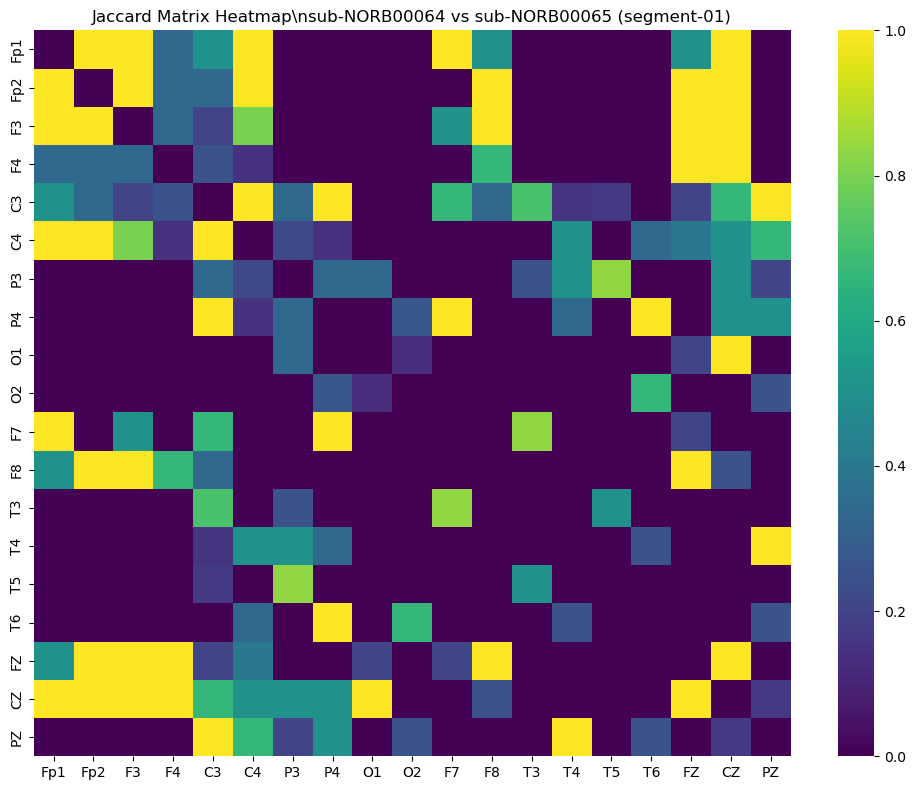

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

if jaccard_results:
    first_segment = list(jaccard_results.keys())[0]
    if jaccard_results[first_segment]:
        sample_pair = list(jaccard_results[first_segment].keys())[0]
        print(f"Example Node-Pair Jaccard Matrix")
        print(f"Segment: {first_segment}")
        print(f"Subject Pair: {sample_pair[0]} and {sample_pair[1]}")
        
        # Display the dataframe
        df_example = jaccard_results[first_segment][sample_pair]
        display(df_example.head())
        
        # Plot the heatmap
        plt.figure(figsize=(10, 8))
        sns.heatmap(df_example, annot=False, cmap='viridis', vmin=0, vmax=1)
        plt.title(f"Jaccard Matrix Heatmap\\n{sample_pair[0]} vs {sample_pair[1]} ({first_segment})")
        plt.tight_layout()
        plt.show()
else:
    print("No Jaccard matrices found to display.")


Calculated average Jaccard matrix for 190 subject pairs.

Example Averaged Jaccard Matrix for sub-NORB00064 and sub-NORB00065
(Averaged over 8 segments)


,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T3,T4,T5,T6,FZ,CZ,PZ
Fp1,0.000000,0.677083,0.791667,0.618056,0.306548,0.604167,0.000000,0.083333,0.06250,0.009615,0.593750,0.531250,0.06250,0.000000,0.0625,0.250000,0.687500,0.562500,0.000000
Fp2,0.677083,0.000000,0.916667,0.614583,0.395833,0.833333,0.062500,0.000000,0.00000,0.000000,0.479167,0.625000,0.06250,0.187500,0.0000,0.166667,0.562500,0.427083,0.150000
F3,0.791667,0.916667,0.000000,0.854167,0.478125,0.808333,0.145833,0.000000,0.12500,0.025000,0.583333,0.791667,0.12500,0.250000,0.1250,0.250000,0.937500,0.531250,0.062500
F4,0.618056,0.614583,0.854167,0.000000,0.302083,0.460714,0.150000,0.000000,0.00000,0.000000,0.437500,0.739583,0.00000,0.468750,0.0000,0.250000,0.608333,0.650000,0.142857
C3,0.306548,0.395833,0.478125,0.302083,0.000000,0.578274,0.453125,0.496528,0.21875,0.291667,0.513690,0.291667,0.54798,0.412088,0.1250,0.187500,0.483482,0.812500,0.614583


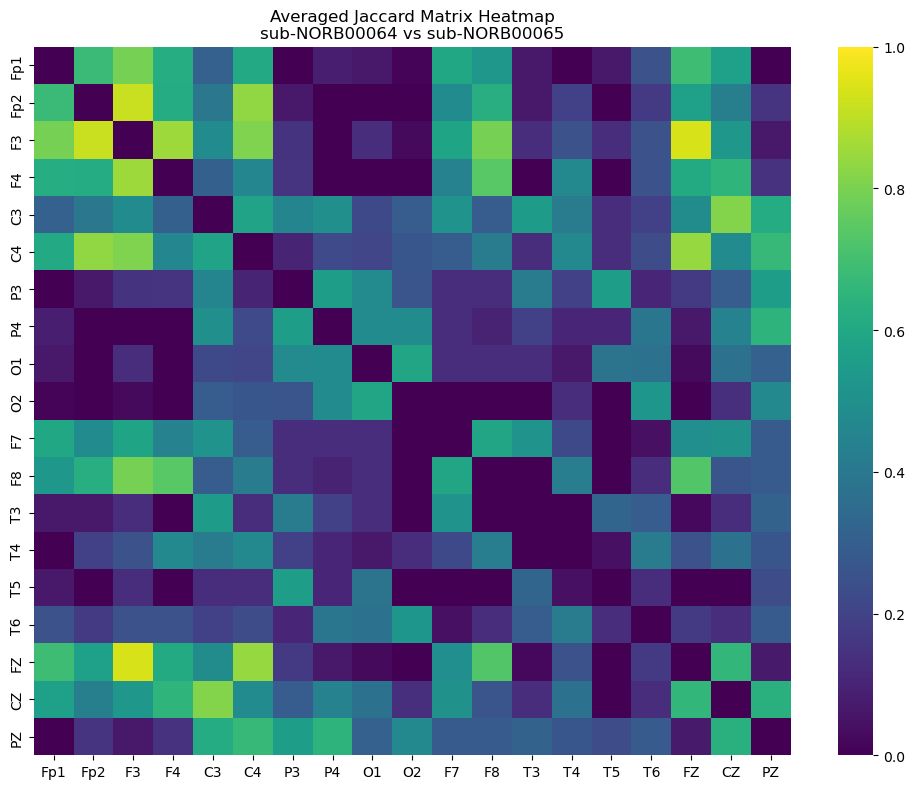

In [7]:
# Dictionary to store the averaged Jaccard matrix for each subject pair
# average_jaccard_results[(sub_x, sub_y)] = average_matrix_dataframe
average_jaccard_results = {}

# We will iterate over all subject pairs found in the first segment
if jaccard_results and segment_keys[0] in jaccard_results:
    subject_pairs = list(jaccard_results[segment_keys[0]].keys())
    
    for pair in subject_pairs:
        # Collect all available segment matrices for this pair
        matrices_for_pair = []
        for segment in segment_keys:
            if segment in jaccard_results and pair in jaccard_results[segment]:
                matrices_for_pair.append(jaccard_results[segment][pair])
        
        # Calculate the element-wise average matrix if we have any matrices
        if matrices_for_pair:
            # Sum all dataframes and divide by count
            sum_matrix = sum(matrices_for_pair)
            avg_matrix = sum_matrix / len(matrices_for_pair)
            
            average_jaccard_results[pair] = avg_matrix

    print(f"Calculated average Jaccard matrix for {len(average_jaccard_results)} subject pairs.")
    
    # --- Show an example of the averaged matrix and its heatmap ---
    sample_pair = subject_pairs[0]
    print(f"\nExample Averaged Jaccard Matrix for {sample_pair[0]} and {sample_pair[1]}")
    print(f"(Averaged over {len(matrices_for_pair)} segments)")
    
    df_avg_example = average_jaccard_results[sample_pair]
    display(df_avg_example.head())
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(df_avg_example, annot=False, cmap='viridis', vmin=0, vmax=1)
    plt.title(f"Averaged Jaccard Matrix Heatmap\n{sample_pair[0]} vs {sample_pair[1]}")
    plt.tight_layout()
    plt.show()

else:
    print("No Jaccard results found to average.")



Heatmap shape: (190, 171)
Valid subject pairs used: 190


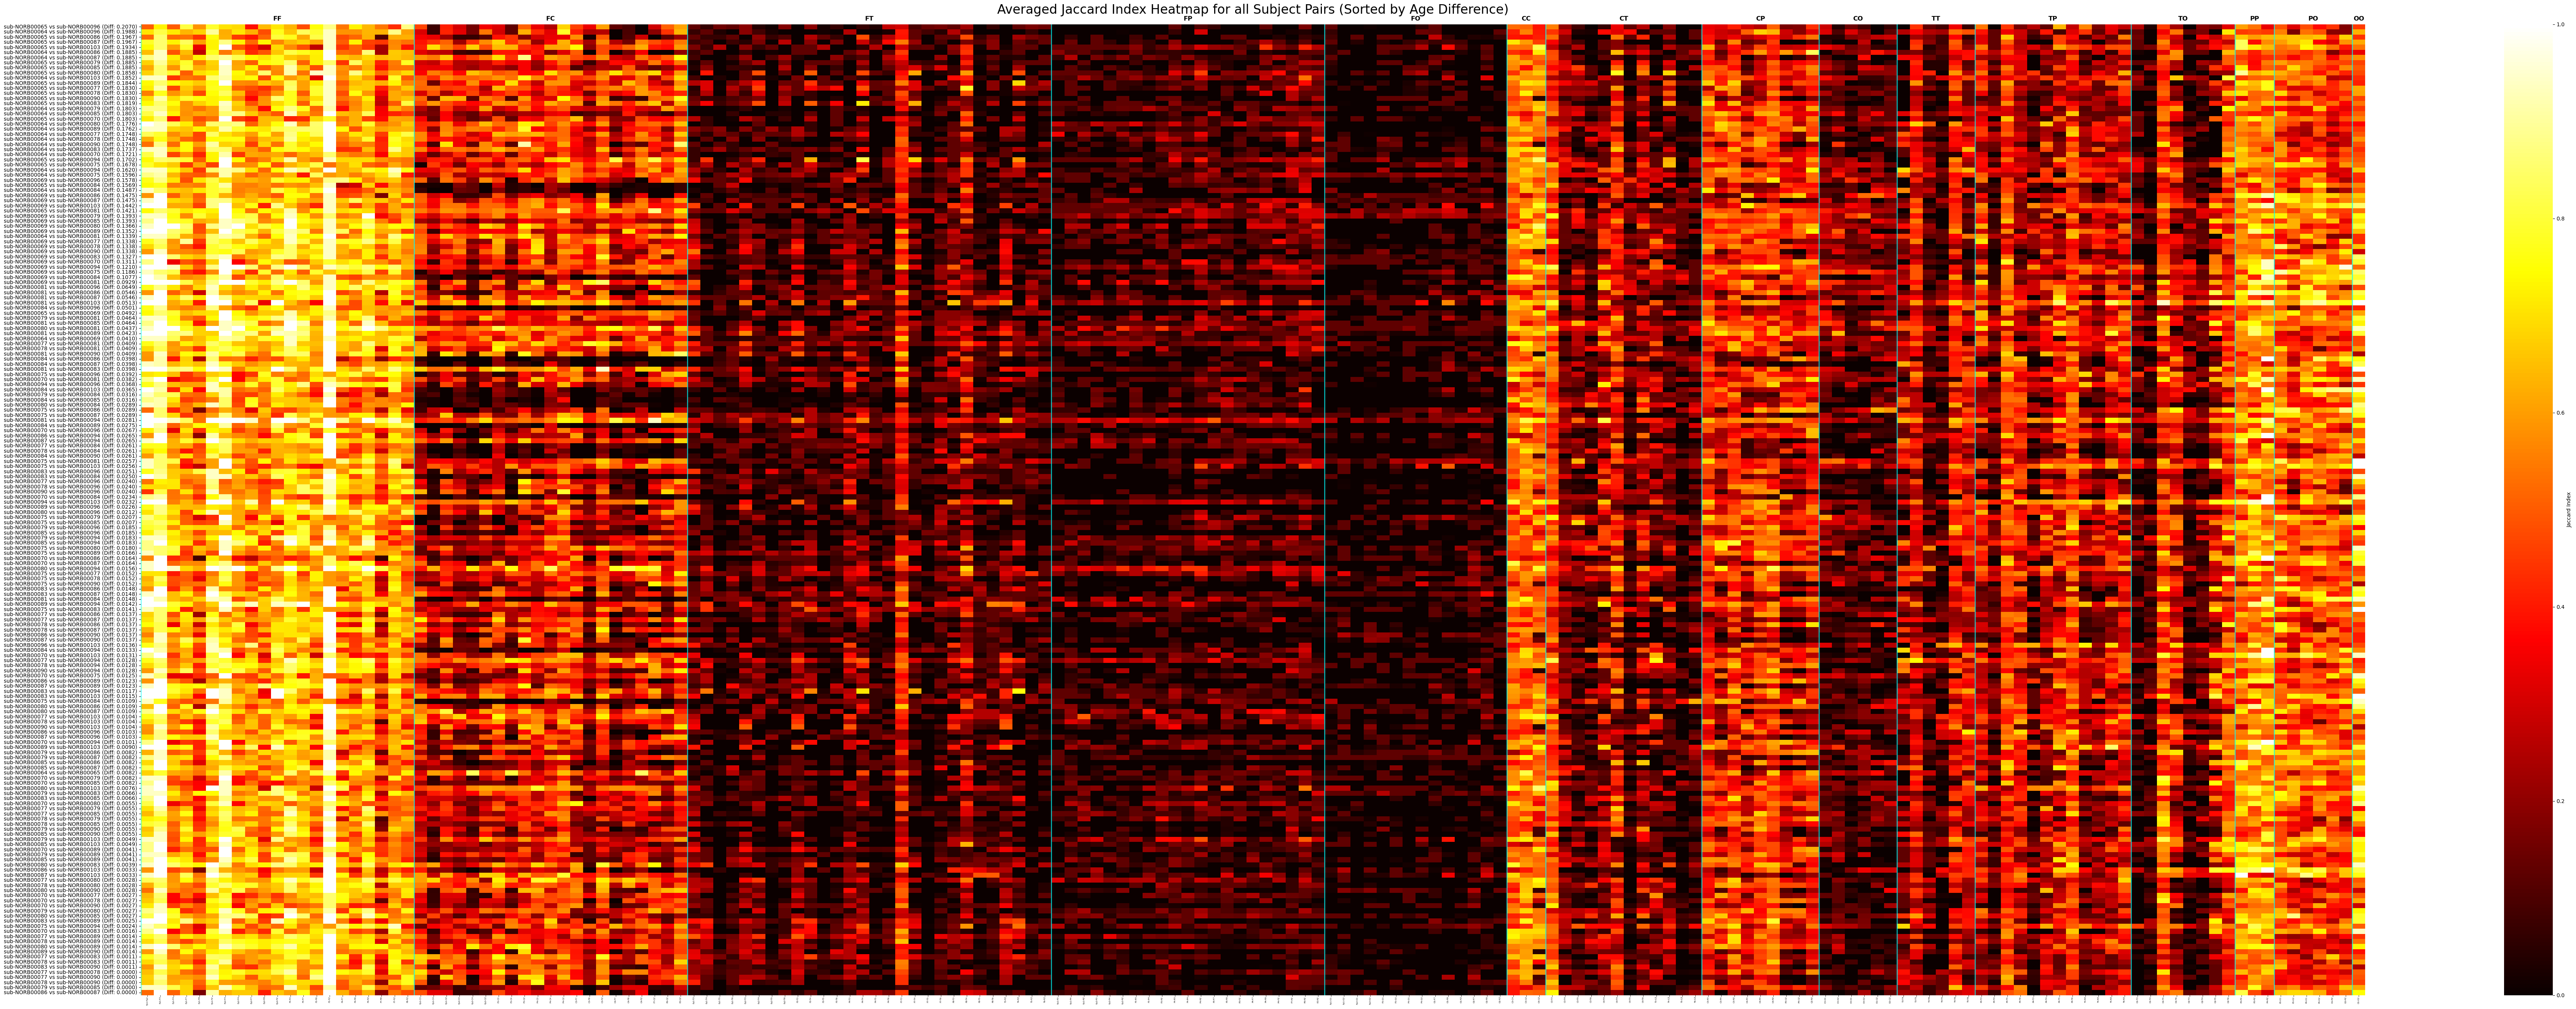

In [8]:
# Extract all unique edge pairs from the first averaged matrix
if average_jaccard_results:
    first_avg_mat = list(average_jaccard_results.values())[0]
    
    # Get all combinations of electrodes (columns of the dataframe)
    nodes = list(first_avg_mat.columns)
    edge_pairs = list(itertools.combinations(nodes, 2))
    
    # --- Sort the edge pairs by band order ---
    # The requested order groups by regions: FF, FC, FT, FP, FO, CC, CT, CP, CO, TT, TP, TO, PP, PO, OO
    band_order = 'FCTPO'
    order_keys = [a + b for i, a in enumerate(band_order) for b in band_order[i:]]
    order_map = {k: i for i, k in enumerate(order_keys)}
    
    def band_key(edge):
        a, b = edge
        # The first character of the electrode name determines its region (e.g., 'Fp1' -> 'F')
        return ''.join(sorted((a[0].upper(), b[0].upper()), key=lambda c: band_order.index(c)))
    
    sorted_edge_pairs = sorted(edge_pairs, key=lambda ep: order_map[band_key(ep)])
    edge_labels = [f"{a}-{b}" for a, b in sorted_edge_pairs]
    
    heatmap_rows = []
    heatmap_indices = []
    
    # --- Sort subject pairs by age difference ---
    try:
        age_df = pd.read_csv('age_acq_time_sorted.csv')
        age_lookup = dict(zip(age_df['label'], age_df['age_acq_time']))
    except FileNotFoundError:
        print("Warning: age_acq_time_sorted.csv not found, proceeding without age sorting.")
        age_lookup = {}
        
    pair_age_diffs = []
    for pair in average_jaccard_results.keys():
        sub1_label = f"{pair[0]}_ses-1"
        sub2_label = f"{pair[1]}_ses-1"
        
        if sub1_label in age_lookup and sub2_label in age_lookup:
            age_diff = abs(age_lookup[sub1_label] - age_lookup[sub2_label])
        else:
            age_diff = float('inf')
            
        pair_age_diffs.append({'pair': pair, 'age_diff': age_diff})
        
    # Sort descending so the least age difference is at the bottom of the heatmap
    sorted_pair_dicts = sorted(pair_age_diffs, key=lambda x: x['age_diff'], reverse=True)
    
    for pair_dict in sorted_pair_dicts:
        pair = pair_dict['pair']
        age_diff = pair_dict['age_diff']
        avg_mat = average_jaccard_results[pair]
        
        # Extract the Jaccard index for each sorted edge pair
        row_values = []
        for a, b in sorted_edge_pairs:
            if a in avg_mat.index and b in avg_mat.columns:
                val = avg_mat.loc[a, b]
                row_values.append(val)
            else:
                row_values.append(np.nan)
                
        heatmap_rows.append(row_values)
        
        # Add age diff to the label for clarity
        if age_diff != float('inf'):
            heatmap_indices.append(f"{pair[0]} vs {pair[1]} (Diff: {age_diff:.4f})")
        else:
            heatmap_indices.append(f"{pair[0]} vs {pair[1]}")
        
    heatmap_df = pd.DataFrame(
        heatmap_rows,
        index=heatmap_indices,
        columns=edge_labels
    )
    
    print(f"\nHeatmap shape: {heatmap_df.shape}")
    print(f"Valid subject pairs used: {len(heatmap_df)}")
    
    if not heatmap_df.empty:
        # Dimensions based on the reference notebook style
        fig_width = max(72, len(heatmap_df.columns) * 0.45)
        fig_height = max(18, len(heatmap_df.index) * 0.14)
        
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))
        sns.heatmap(
            heatmap_df,
            cmap='hot',
            cbar_kws={'label': 'Jaccard Index'},
            vmin=0,
            vmax=1,
            ax=ax,
            xticklabels=False,
            yticklabels=True,
        )
        
        ax.set_xticks(np.arange(len(heatmap_df.columns)) + 0.5)
        ax.set_xticklabels(heatmap_df.columns, rotation=90, fontsize=4)
        ax.tick_params(axis='x', which='both', length=2, pad=1)
        
        # --- Draw vertical lines separating the band groups ---
        col_band_keys = [band_key(ep) for ep in sorted_edge_pairs]
        unique_band_keys = [k for k in order_keys if k in col_band_keys]
        
        for key in unique_band_keys:
            indices = [i for i, k in enumerate(col_band_keys) if k == key]
            if indices:
                # Add a vertical line at the start of each group
                start_idx = indices[0]
                ax.axvline(x=start_idx, color='cyan', linestyle='-', linewidth=2, alpha=0.7)
                
                # Add text label for the group right above the chart
                ax.text(start_idx + len(indices)/2, -0.5, key, 
                        ha='center', va='bottom', color='black', fontsize=12, fontweight='bold')
        
        plt.title("Averaged Jaccard Index Heatmap for all Subject Pairs (Sorted by Age Difference)", fontsize=24, pad=20)
        plt.tight_layout()
        plt.show()
else:
    print("No averaged Jaccard matrices available to plot.")
